# Computer Vision — Lab Task 7 (CLO-1)
**Name:** Sarim Azhar  **Roll No:** 247076
**Instructor:** Ayesha Sahar

**Task:** Implement and compare three CNNs (Basic, Deeper, Wider) on the **iBeans** bean-leaf disease dataset using TensorFlow/Keras.

Dataset: https://github.com/AI-Lab-Makerere/ibean/ — leaf images in 3 classes: `angular_leaf_spot`, `bean_rust`, `healthy`. The repo ships an official train / validation / test split, which is used here so every model sees exactly the same split.

> **Note on the output layer:** the task sheet says `Dense(10, Softmax)` (carried over from MNIST), but iBeans has **3 classes**, so the output layer uses `Dense(3, softmax)`. Everything else follows the specification exactly.

In [2]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Activity 1: Download the dataset
The official iBeans train / validation / test zips are downloaded and extracted. The Google Storage links in the GitHub README now return *403 Forbidden*, so the identical files are downloaded from the authors' Hugging Face mirror (`AI-Lab-Makerere/beans`). Each zip contains one folder per class.

In [3]:
import zipfile

# The original Google Storage links (storage.googleapis.com/ibeans) now return 403 Forbidden.
# The same official zips are mirrored by the dataset authors on Hugging Face.
BASE_URL = "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/main/data/"
DATA_DIR = "/content/ibeans" if os.path.exists("/content") else os.path.abspath("./ibeans")
os.makedirs(DATA_DIR, exist_ok=True)

def download_split(split):
    zip_path = tf.keras.utils.get_file(
        fname=f"{split}.zip", origin=BASE_URL + f"{split}.zip",
        cache_dir=DATA_DIR, cache_subdir="zips"
    )
    out_dir = os.path.join(DATA_DIR, split)
    if not os.path.exists(out_dir):
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(out_dir)
    # find the folder that directly contains the class folders
    for dirpath, dirnames, _ in os.walk(out_dir):
        if "healthy" in dirnames:
            return dirpath
    raise FileNotFoundError(f"Class folders not found for {split}")

TRAIN_DIR = download_split("train")
VAL_DIR   = download_split("validation")
TEST_DIR  = download_split("test")

for name, d in [("Train", TRAIN_DIR), ("Validation", VAL_DIR), ("Test", TEST_DIR)]:
    counts = {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))
              if os.path.isdir(os.path.join(d, c))}
    print(f"{name:10s} {counts}  total={sum(counts.values())}")

143812152/143812152 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
18504213/18504213 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
17708541/17708541 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train      {'angular_leaf_spot': 345, 'bean_rust': 348, 'healthy': 342}  total=1035
Validation {'angular_leaf_spot': 44, 'bean_rust': 45, 'healthy': 44}  total=133
Test       {'angular_leaf_spot': 43, 'bean_rust': 43, 'healthy': 42}  total=128


## Activity 2: Load and preprocess the images
- Images are resized from 500×500 to **128×128** to keep training time and the number of Dense-layer parameters manageable.
- Pixel values are scaled from 0–255 to 0–1 with a `Rescaling` layer inside the model.
- Labels are integers (0, 1, 2), so `sparse_categorical_crossentropy` is used.
- The **same** batch size (32) and datasets are reused for all three models.

In [4]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 20          # same maximum number of epochs for every model

def load(dir_, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        dir_, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="int", shuffle=shuffle, seed=SEED
    )

train_ds = load(TRAIN_DIR, shuffle=True)
val_ds   = load(VAL_DIR,   shuffle=False)
test_ds  = load(TEST_DIR,  shuffle=False)

CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 1034 files belonging to 3 classes.
Found 133 files belonging to 3 classes.
Found 128 files belonging to 3 classes.
Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


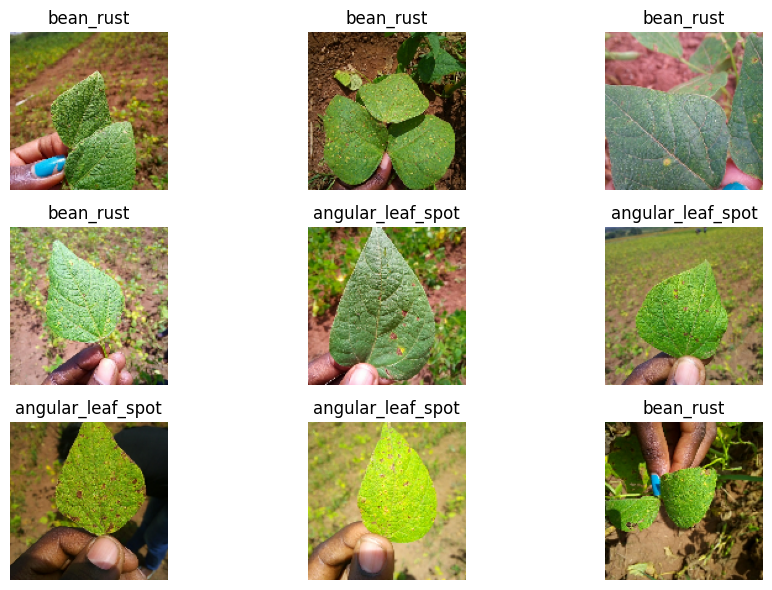

Batch shape: (32, 128, 128, 3) | pixel range: 0.0 to 255.0


In [5]:
# Show sample images
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()
print("Batch shape:", images.shape, "| pixel range:", images.numpy().min(), "to", images.numpy().max())

## Activity 3: Define the three models
| Model | Architecture |
|---|---|
| **Model 1 – Basic** | Conv2D(16,3×3) → MaxPool(2×2) → Conv2D(32,3×3) → MaxPool(2×2) → Flatten → Dense(64, ReLU) → Dropout(0.2) → Dense(softmax) |
| **Model 2 – Deeper** | Model 1 + Conv2D(64, 3×3) after the second MaxPool |
| **Model 3 – Wider** | Model 1 with filters 32 and 64 instead of 16 and 32 |

All conv layers use ReLU and `padding="same"` (as in Lab 08). One builder function is used so the only thing that changes between models is the convolution block.

In [6]:
def build_model(conv_filters, extra_conv=None, name="cnn"):
    """conv_filters: filters for the two conv+pool blocks.
       extra_conv: filters for an optional third conv layer after the 2nd pool."""
    layers = [
        tf.keras.layers.Input(shape=IMG_SIZE + (3,)),
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(conv_filters[0], (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(conv_filters[1], (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
    ]
    if extra_conv:
        layers.append(tf.keras.layers.Conv2D(extra_conv, (3, 3), activation="relu", padding="same"))
    layers += [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ]
    model = tf.keras.Sequential(layers, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),   # same optimizer for all
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model_specs = {
    "Model 1 - Basic CNN":  dict(conv_filters=(16, 32), extra_conv=None, name="basic_cnn"),
    "Model 2 - Deeper CNN": dict(conv_filters=(16, 32), extra_conv=64,   name="deeper_cnn"),
    "Model 3 - Wider CNN":  dict(conv_filters=(32, 64), extra_conv=None, name="wider_cnn"),
}

for title, spec in model_specs.items():
    print("\n" + "=" * 70 + f"\n{title}")
    build_model(**spec).summary()


Model 1 - Basic CNN


Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,097,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,102,499 (8.02 MB)

 Trainable params: 2,102,499 (8.02 MB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     4,194,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,955 (16.07 MB)

 Trainable params: 4,213,955 (16.07 MB)

 Non-trainable params: 0 (0.00 B)

## Activity 4: Train all three models
Identical settings for every model: same train/validation split, Adam (lr = 0.001), batch size 32, maximum 20 epochs.
`EarlyStopping` (patience 4, restores best weights) and the random seed is reset before each model so the comparison is fair.

In [7]:
histories, trained = {}, {}

for title, spec in model_specs.items():
    print("\n" + "=" * 70 + f"\nTraining {title}")
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED); np.random.seed(SEED); random.seed(SEED)

    model = build_model(**spec)
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=1,
    )
    histories[title] = history.history
    trained[title] = model


Training Model 1 - Basic CNN
Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 223ms/step - accuracy: 0.4110 - loss: 1.1861 - val_accuracy: 0.6466 - val_loss: 0.9842
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6248 - loss: 0.8591 - val_accuracy: 0.7068 - val_loss: 0.7093
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7205 - loss: 0.6767 - val_accuracy: 0.6917 - val_loss: 0.6831
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7785 - loss: 0.5647 - val_accuracy: 0.6992 - val_loss: 0.6871
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8114 - loss: 0.4913 - val_accuracy: 0.7143 - val_loss: 0.6271
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8279 - loss: 0.4278 - val_accuracy: 0.7895 - val_loss: 0.5685
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8820 - loss: 0.3305 - val_accuracy: 0.7744 - val_loss: 0.5336
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9081 - loss: 0.262

## Activity 5: Training curves

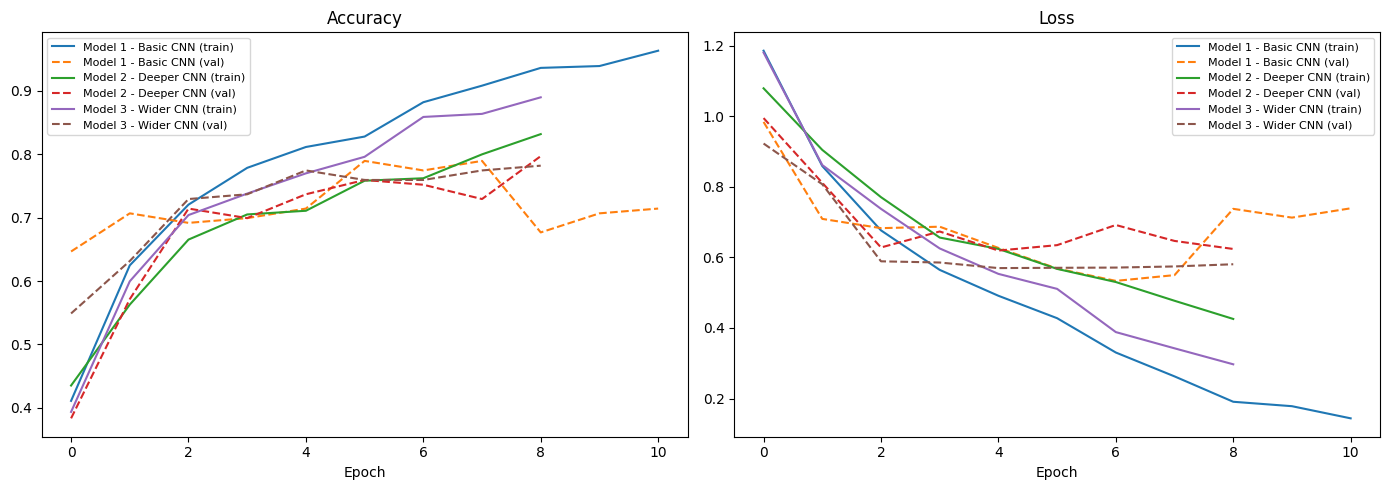

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for title, h in histories.items():
    axes[0].plot(h["accuracy"], label=f"{title} (train)")
    axes[0].plot(h["val_accuracy"], "--", label=f"{title} (val)")
    axes[1].plot(h["loss"], label=f"{title} (train)")
    axes[1].plot(h["val_loss"], "--", label=f"{title} (val)")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Loss");     axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Activity 6: Evaluate and compare
For each model: training accuracy and validation accuracy are taken from the epoch whose weights were restored (best `val_loss`), then the model is evaluated once on the unseen test set.

In [9]:
rows = []
for title, model in trained.items():
    h = histories[title]
    best = int(np.argmin(h["val_loss"]))           # epoch restored by EarlyStopping
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    rows.append({
        "Model": title,
        "Epochs run": len(h["loss"]),
        "Best epoch": best + 1,
        "Train accuracy": h["accuracy"][best],
        "Val accuracy": h["val_accuracy"][best],
        "Test accuracy": test_acc,
        "Test loss": test_loss,
        "Trainable params": trainable,
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.style.format({
    "Train accuracy": "{:.2%}", "Val accuracy": "{:.2%}",
    "Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Trainable params": "{:,}",
}))

,Epochs run,Best epoch,Train accuracy,Val accuracy,Test accuracy,Test loss,Trainable params
Model,,,,,,,
Model 1 - Basic CNN,11,7,88.20%,77.44%,78.12%,0.5505,"2,102,499"
Model 2 - Deeper CNN,9,5,71.08%,73.68%,77.34%,0.5842,"4,218,147"
Model 3 - Wider CNN,9,5,76.98%,77.44%,80.47%,0.5334,"4,213,955"


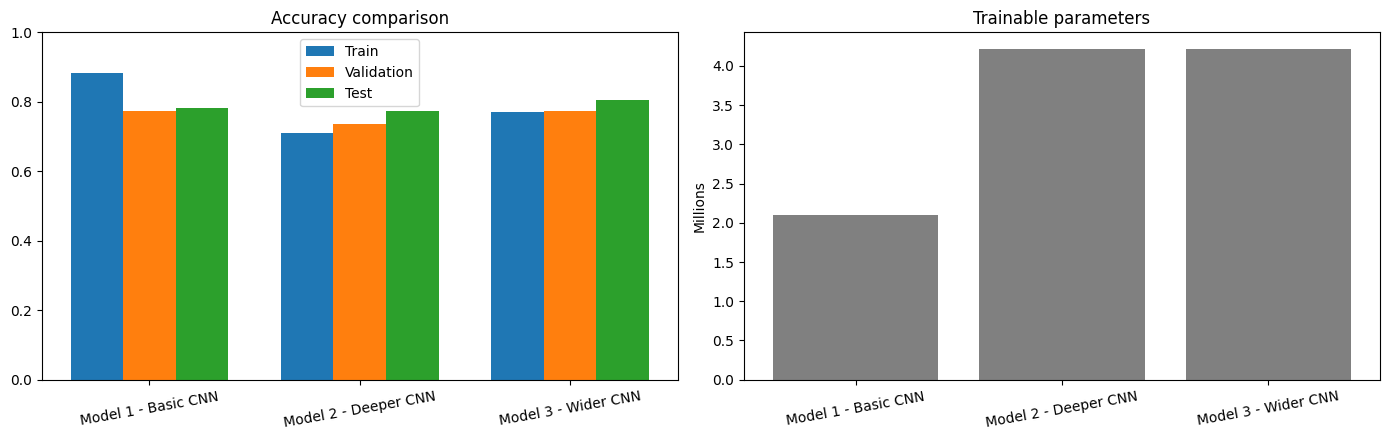

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(results)); w = 0.25
axes[0].bar(x - w, results["Train accuracy"], w, label="Train")
axes[0].bar(x,     results["Val accuracy"],   w, label="Validation")
axes[0].bar(x + w, results["Test accuracy"],  w, label="Test")
axes[0].set_xticks(x); axes[0].set_xticklabels(results.index, rotation=10)
axes[0].set_ylim(0, 1); axes[0].set_title("Accuracy comparison"); axes[0].legend()

axes[1].bar(results.index, results["Trainable params"] / 1e6, color="gray")
axes[1].set_ylabel("Millions"); axes[1].set_title("Trainable parameters")
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

### Per-class performance on the test set

In [11]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
for title, model in trained.items():
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    print("=" * 70 + f"\n{title}\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred), "\n")

Model 1 - Basic CNN

                   precision    recall  f1-score   support

angular_leaf_spot      0.691     0.884     0.776        43
        bean_rust      0.806     0.581     0.676        43
          healthy      0.881     0.881     0.881        42

         accuracy                          0.781       128
        macro avg      0.793     0.782     0.777       128
     weighted avg      0.792     0.781     0.777       128

Confusion matrix:
 [[38  3  2]
 [15 25  3]
 [ 2  3 37]] 

Model 2 - Deeper CNN

                   precision    recall  f1-score   support

angular_leaf_spot      0.853     0.674     0.753        43
        bean_rust      0.714     0.698     0.706        43
          healthy      0.769     0.952     0.851        42

         accuracy                          0.773       128
        macro avg      0.779     0.775     0.770       128
     weighted avg      0.779     0.773     0.769       128

Confusion matrix:
 [[29 10  4]
 [ 5 30  8]
 [ 0  2 40]] 

Model 3 -

## Discussion
*(Update the numbers below from your own run — results vary slightly between runs and GPUs.)*

- **Trainable parameters:** Most parameters sit in the first `Dense(64)` layer, because it is connected to every value of the flattened feature map. Model 2 adds a 64-filter conv layer *without* an extra pooling layer, so its flattened vector doubles (32×32×32 → 32×32×64) and its parameter count roughly doubles. Model 3 ends with 64 filters too, so it lands at a very similar count. Model 1 is the smallest (~2.1 M vs ~4.2 M).
- **Accuracy:** Compare the train vs. validation columns. A large gap (e.g. train ≈ 100 %, val much lower) means the model is overfitting the ~1,000 training images.
- **Deeper vs. Wider:** The deeper model learns more complex features (a third level of feature hierarchy), while the wider model learns more low-level features per layer. Note which one gives the better **test** accuracy and test loss.
- **Small test set:** With only 128 test images, one wrong prediction changes test accuracy by about 0.8 percentage points, so small differences between models may be partly down to chance.
- **Conclusion:** State which model gives the best trade-off between test accuracy and number of parameters.